# DART in XGBoost

[Master Tree Ensemble Models course](https://www.trainindata.com/p/master-tree-ensemble-models)

In this notebook, we train XGBoost with DART to predict the rent price of an apartment. We train a model with the default parameters and early stopping, train DART with the same number of trees, and then see how the drop rate and the skip rate change it.

XGBoost ships a scikit-learn wrapper, `XGBRegressor` and `XGBClassifier`, which fits into scikit-learn pipelines and searches. In this course we use the native API, `xgb.train` with a `DMatrix`, because it exposes the full feature set of the library.

In [1]:
import time

import matplotlib.pyplot as plt
import pandas as pd
import xgboost as xgb
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor

### Load data

We use the apartment rent data that we prepared in the notebook of the folder prepare-data.

In [2]:
df = pd.read_csv("../prepare-data/apartment_rent.csv", index_col="time")
df.head()

,category,bathrooms,bedrooms,fee,has_photo,pets_allowed,price,square_feet,cityname,state,...,amenity_Patio/Deck,amenity_Playground,amenity_Pool,amenity_Refrigerator,amenity_Storage,amenity_TV,amenity_Tennis,amenity_View,amenity_Washer Dryer,amenity_Wood Floors
time,,,,,,,,,,,,,,,,,,,,,
2018-12-07 09:20:18,housing/rent/apartment,1.0,1.0,No,Thumbnail,Not specified,1191.0,800.0,Atlanta,GA,...,0,0,0,0,0,1,0,0,0,0
2018-12-07 09:20:32,housing/rent/apartment,2.0,4.0,No,Yes,Not specified,1450.0,1880.0,Orange Park,FL,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:44,housing/rent/apartment,2.0,3.0,No,Yes,Not specified,1395.0,1661.0,Orange Park,FL,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:55,housing/rent/apartment,2.0,3.0,No,Yes,Not specified,1255.0,1400.0,Orange Park,FL,...,0,0,0,0,0,0,1,0,0,0
2018-12-07 09:20:58,housing/rent/apartment,2.0,2.0,No,Yes,Not specified,1693.0,1346.0,Atlanta,GA,...,0,0,0,0,0,1,0,0,0,0


In [3]:
# XGBoost splits on categories directly, so we keep them as pandas categories instead of integers
categorical_vars = df.select_dtypes("str").columns
df[categorical_vars] = df[categorical_vars].astype("category")

# XGBoost takes missing values, so we leave NaN as it is

df.head()

,category,bathrooms,bedrooms,fee,has_photo,pets_allowed,price,square_feet,cityname,state,...,amenity_Patio/Deck,amenity_Playground,amenity_Pool,amenity_Refrigerator,amenity_Storage,amenity_TV,amenity_Tennis,amenity_View,amenity_Washer Dryer,amenity_Wood Floors
time,,,,,,,,,,,,,,,,,,,,,
2018-12-07 09:20:18,housing/rent/apartment,1.0,1.0,No,Thumbnail,Not specified,1191.0,800.0,Atlanta,GA,...,0,0,0,0,0,1,0,0,0,0
2018-12-07 09:20:32,housing/rent/apartment,2.0,4.0,No,Yes,Not specified,1450.0,1880.0,Orange Park,FL,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:44,housing/rent/apartment,2.0,3.0,No,Yes,Not specified,1395.0,1661.0,Orange Park,FL,...,0,0,0,0,0,0,0,0,0,0
2018-12-07 09:20:55,housing/rent/apartment,2.0,3.0,No,Yes,Not specified,1255.0,1400.0,Orange Park,FL,...,0,0,0,0,0,0,1,0,0,0
2018-12-07 09:20:58,housing/rent/apartment,2.0,2.0,No,Yes,Not specified,1693.0,1346.0,Atlanta,GA,...,0,0,0,0,0,1,0,0,0,0


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns="price"),
    df["price"],
    test_size=0.3,
    random_state=0,
)

X_train.shape, X_test.shape

((69872, 39), (29946, 39))

In [5]:
# the mean rent price
y_train.mean(), y_test.mean()

(np.float64(1527.515742929929), np.float64(1526.5632805716957))

### Build the data containers

The native API takes its data in a `DMatrix`. We build each one once and reuse it in every model of the notebook.

In [6]:
dtrain = xgb.DMatrix(X_train, label=y_train, enable_categorical=True)
dtest = xgb.DMatrix(X_test, label=y_test, enable_categorical=True)

dtrain.num_row(), dtest.num_row()

(69872, 29946)

### Train the model with the default parameters

We show the hyperparameters with their default values, so that we can see the effect of changing them later on.

In [7]:
params = {
    # learning task
    "objective": "reg:squarederror",
    "eval_metric": "rmse",

    # tree structure and algorithm
    "booster": "gbtree",
    "tree_method": "hist",
    "eta": 0.3,                    # the learning rate
    "grow_policy": "depthwise",
    "max_bin": 256,
    "max_depth": 6,
    "max_leaves": 0,               # 0 means no limit
    "min_child_weight": 1,

    # dart
    "rate_drop": 0,                # 0 means no dropout
    "one_drop": 0,
    "skip_drop": 0,
    "sample_type": "uniform",
    "normalize_type": "tree",

    # regularization
    "gamma": 0,
    "lambda": 1,
    "alpha": 0,

    # sampling
    "subsample": 1,
    "sampling_method": "uniform",
    "colsample_bytree": 1,
    "colsample_bylevel": 1,
    "colsample_bynode": 1,

    # categorical features
    "max_cat_to_onehot": 4,
    "max_cat_threshold": 64,

    # hardware and reproducibility
    "device": "cpu",
    "nthread": 4,                  # fixed, so that the timings are comparable
    "seed": 0,
}

> **Note:** From XGBoost 3.3 on, the dropout parameters work with the default booster, `gbtree`, and a `rate_drop` above 0 turns DART on. In older versions, we turn it on with `booster="dart"`, which still works in newer versions but raises a deprecation warning.

We let XGBoost add up to 2000 trees and stop when the rmse in the test set has not improved for 50 rounds. Here, to keep the notebook short, the test set plays the role of the validation set. In a real project, we would hold out a separate validation set, because choosing the number of trees on the test set makes the test score optimistic.

In [8]:
evals_result = {}

booster = xgb.train(
    params,
    dtrain,
    num_boost_round=2000,
    evals=[(dtrain, "train"), (dtest, "test")],
    early_stopping_rounds=50,
    evals_result=evals_result,
    verbose_eval=100,
)

[0]	train-rmse:736.09868	test-rmse:714.64695


[100]	train-rmse:217.87119	test-rmse:473.00414


[200]	train-rmse:180.60570	test-rmse:467.39545


[300]	train-rmse:159.61362	test-rmse:465.87587


[400]	train-rmse:146.16287	test-rmse:465.21978


[433]	train-rmse:142.12382	test-rmse:465.41892


In [9]:
# best_iteration counts from 0, so the best model has one tree more
num_rounds = booster.best_iteration + 1

print(f"best number of trees: {num_rounds}, trees in the booster: {booster.num_boosted_rounds()}")

best number of trees: 384, trees in the booster: 434


The test rmse reached its lowest value with 384 trees, but the booster holds 434, because early stopping waited 50 more rounds. XGBoost keeps those extra trees, and `predict` uses all of them by default, while its scikit-learn wrapper predicts with the best round, and LightGBM and CatBoost return a model cut to the best round. So here we cut the booster ourselves.

In [10]:
# keep only the trees up to the best round
booster = booster[:booster.best_iteration + 1]

booster.num_boosted_rounds()

384

In [11]:
def evaluate(model, dtrain, y_train, dtest, y_test):
    for name, data, y in [("train", dtrain, y_train), ("test", dtest, y_test)]:
        predictions = model.predict(data)
        rmse = root_mean_squared_error(y, predictions)
        r2 = r2_score(y, predictions)
        print(f"{name} rmse: {rmse:.2f}, r2: {r2:.4f}")


evaluate(booster, dtrain, y_train, dtest, y_test)

train rmse: 148.19, r2: 0.9739


test rmse: 465.02, r2: 0.7140


The model fits the train set much better than the test set, with an rmse of 148 against 465.

### Train the model with DART

We saw in the lecture on DART hyperparameters that in XGBoost, a `rate_drop` above 0 turns DART on: it is the chance that each earlier tree is dropped in a round. We set it to 0.1 and keep the other dropout parameters at their defaults.

The XGBoost documentation warns that early stopping might not be stable with DART, because every round drops a random set of trees. So we train DART without early stopping, for the same 384 trees as the default model. We train the default model again next to it, record the rmse in the test set after every tree, and measure the training time. The times depend on the machine, so we should read them relative to each other.

In [12]:
dart_params = {**params, "rate_drop": 0.1}

In [13]:
def scores(model, dtrain, y_train, dtest, y_test):
    predictions = model.predict(dtest)
    return {
        "train rmse": root_mean_squared_error(y_train, model.predict(dtrain)),
        "test rmse": root_mean_squared_error(y_test, predictions),
        "test r2": r2_score(y_test, predictions),
    }

In [14]:
results = {}
curves = {}
for name, setting in {"gbtree": params, "dart": dart_params}.items():
    evals_result = {}
    start = time.perf_counter()
    model = xgb.train(
        setting,
        dtrain,
        num_boost_round=num_rounds,
        evals=[(dtest, "test")],
        evals_result=evals_result,
        verbose_eval=False,
    )
    seconds = time.perf_counter() - start
    results[name] = {"seconds": seconds, **scores(model, dtrain, y_train, dtest, y_test)}
    curves[name] = evals_result["test"]["rmse"]

dart_results = pd.DataFrame(results).T
dart_results.round(4)

,seconds,train rmse,test rmse,test r2
gbtree,12.0061,148.1858,465.0223,0.7140
dart,213.7274,299.1452,474.8870,0.7017


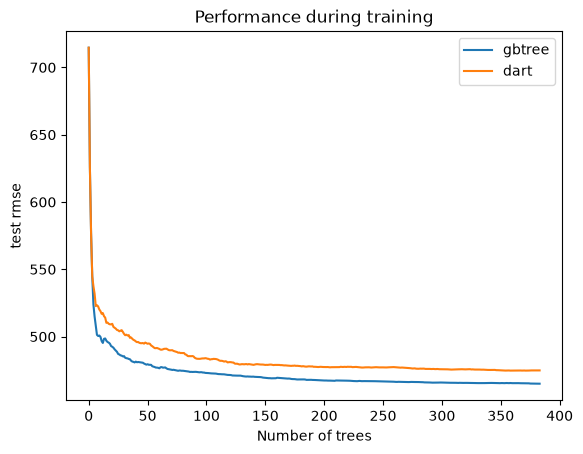

In [15]:
plt.plot(curves["gbtree"], label="gbtree")
plt.plot(curves["dart"], label="dart")
plt.xlabel("Number of trees")
plt.ylabel("test rmse")
plt.title("Performance during training")
plt.legend()
plt.show()

With the same 384 trees, DART trains much slower than the default model and fits the train set less closely, with a train rmse of 299 against 148. Its test rmse of 474.9 is a little higher than the 465.0 of the default model, and its curve falls as smoothly, a little above the curve of the default model.

Let's now change one hyperparameter at a time to understand what is going on. Every setting trains the same 384 trees, without early stopping.

In [16]:
def sweep(base_params, param, values):
    results = {}
    for value in values:
        start = time.perf_counter()
        model = xgb.train({**base_params, param: value}, dtrain, num_boost_round=num_rounds)
        seconds = time.perf_counter() - start
        results[value] = {"seconds": seconds, **scores(model, dtrain, y_train, dtest, y_test)}
    return pd.DataFrame(results).T

In [17]:
def plot_sweep(results, param):
    # the values are not evenly spaced, so we place them at equal distances
    positions = range(len(results))
    plt.plot(positions, results["train rmse"], marker="o", label="train rmse")
    plt.plot(positions, results["test rmse"], marker="o", label="test rmse")
    plt.axhline(dart_results.loc["gbtree", "test rmse"], color="grey", linestyle="dashed", label="gbtree test rmse")
    plt.xticks(positions, results.index)
    plt.xlabel(param)
    plt.ylabel("rmse")
    plt.title(f"Effect of {param}")
    plt.legend()
    plt.show()

### Drop rate

We saw in the lecture on DART hyperparameters that `rate_drop` sets how many trees are dropped in each round, and that a higher value regularizes more strongly. At 0, no tree is dropped, and the model is the classic gradient boosting of the default model.

In [18]:
rate_drop_results = sweep(params, "rate_drop", [0, 0.05, 0.1, 0.2, 0.5])

rate_drop_results.round(4)

,seconds,train rmse,test rmse,test r2
0.00,9.2468,148.1858,465.0223,0.7140
0.05,154.8699,261.9858,457.3221,0.7234
0.10,157.8210,299.1452,474.8870,0.7017
0.20,109.9456,339.1878,493.4792,0.6779
0.50,148.9165,406.0276,523.7333,0.6372


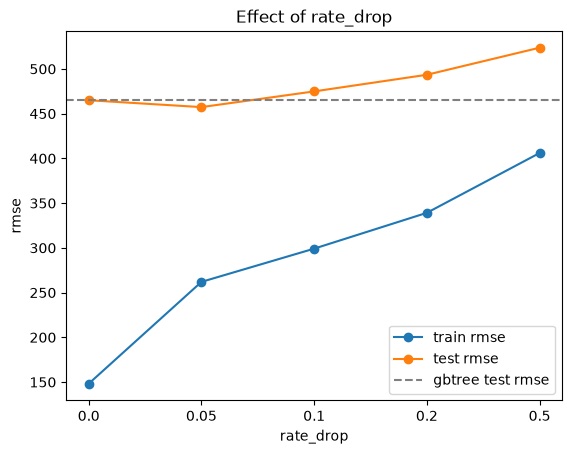

In [19]:
plot_sweep(rate_drop_results, "rate_drop")

At 0, the scores are exactly those of the default model. As `rate_drop` grows, the train rmse rises from 148 to 406 at 0.5, so dropout regularizes more strongly. With the same 384 trees, a small value of 0.05 lowers the test rmse from 465.0 to 457.3, and from 0.1 on the test rmse rises, up to 523.7 at 0.5.

### Skip drop

We saw in the lecture on DART hyperparameters that `skip_drop` is the chance that a round skips dropout completely and adds the new tree just as classic boosting does, so a higher value brings DART closer to classic boosting. We keep `rate_drop` at 0.1, as in our DART model.

In [20]:
skip_drop_results = sweep(dart_params, "skip_drop", [0, 0.25, 0.5, 0.75])

skip_drop_results.round(4)

,seconds,train rmse,test rmse,test r2
0.00,154.0703,299.1452,474.8870,0.7017
0.25,153.6242,224.6977,452.6693,0.7290
0.50,114.8700,181.8511,458.5781,0.7219
0.75,121.1249,162.5054,466.4896,0.7122


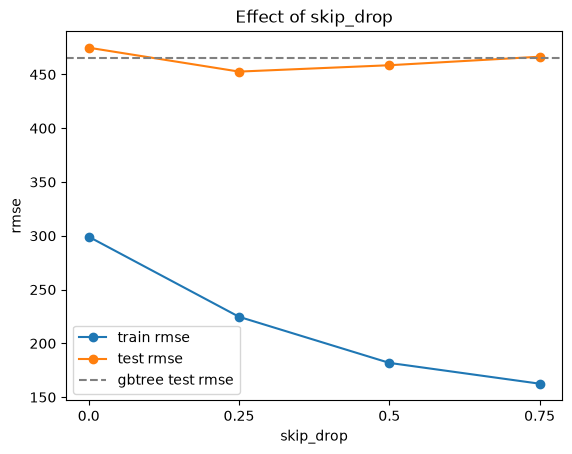

In [21]:
plot_sweep(skip_drop_results, "skip_drop")

As `skip_drop` grows, the train rmse falls from 299 at 0 to 163 at 0.75, close to the 148 of the default model, as DART comes closer to classic boosting. With the same 384 trees, a `skip_drop` of 0.25 gives the lowest test rmse of the notebook, 452.7, and at 0.75 the test rmse of 466.5 is about that of the default model.